### ⚙️ Load GROMACS and Dependencies

> **Note:**  
> These scripts are designed for **ACCRE**.  
> If you are using a different HPC, adjust the module load commands to match your system setup.

#### 🧩 Option 1 – Adjust for Your HPC
Edit the `module load` lines below to match the versions of **GROMACS**, **OpenMPI**, **CUDA**, or other dependencies available on your cluster.

#### 🧪 Option 2 – Use a Manual GROMACS Path
If your cluster does **not** use module environments, remove the `module load` commands and instead source your GROMACS installation manually:
```bash
source /path/to/gromacs/bin/GMXRC


In [2]:
import os
import subprocess

def load_gmx_plumed():
    cmd = """
    module load StdEnvACCRE/2023
    module load gcc/12.3
    module load openmpi/4.1.5
    module load cuda/12.2
    source $HOME/gromacs-2023.5-plumed-mpi/bin/GMXRC
    export PLUMED_KERNEL=$HOME/plumed-2.9.2/lib/libplumedKernel.so
    export LD_LIBRARY_PATH=$HOME/plumed-2.9.2/lib:$LD_LIBRARY_PATH
    export PATH=$HOME/plumed-2.9.2/bin:$PATH
    env
    """
    # run in bash, capture environment
    result = subprocess.run(cmd, shell=True, executable="/bin/bash", capture_output=True, text=True)
    for line in result.stdout.splitlines():
        key, _, value = line.partition("=")
        os.environ[key] = value


In [3]:
load_gmx_plumed()

### 📦 Import Core Libraries

These libraries cover numerical operations, plotting, system utilities, and data handling.

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import subprocess
import os
from contextlib import contextmanager
import re
import pandas
import pathlib

Cd into working directory, if the script is placed in the working directory and run from it, this step is not necessary

In [5]:
%cd /panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Replica_Publish

/panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Replica_Publish


/cvmfs/soft.computecanada.ca/easybuild/software/2023/x86-64-v3/Compiler/gcccore/ipykernel/2025a/lib/python3.12/site-packages/IPython/core/magics/osm.py:417: UserWarning: This is now an optional IPython functionality, setting dhist requires you to install the `pickleshare` library.
  self.shell.db['dhist'] = compress_dhist(dhist)[-100:]


## 🧮 RMSD and Rg Analysis (SMOG Trajectories)

Batch script to compute **radius of gyration (Rg)** and **RMSD** 📊 for all SMOG replica trajectories across temperatures.

- 🔬 Systems processed: **3PRG**, **6ONJ**, **6ONI**
- 🌡️ Loops over all temperature-specific trajectories
- 🧱 Uses a common reference structure (`confout.gro`)
- 📁 Outputs written to a structured `Advanced_Analysis/` directory

Generated outputs (per system and temperature):
- `Rg_{system}_{T}.xvg`
- `RMSD_{system}_{T}.xvg`

These outputs are used downstream for comparative analysis and generation of publication-quality figures 🎨.


In [ ]:
%%bash
set -e

# ==============================
# CONFIGURATION
# ==============================
systems=("3PRG" "6ONJ" "6ONI")
dirs=("100" "102" "104" "106" "106.5" "107" "107.5" "108" "108.5" "109" "109.5" "110" "112" "114" "116" "118")

# ==============================
# CREATE ADVANCED ANALYSIS TREE
# ==============================
mkdir -p Advanced_Analysis

for sys in "${systems[@]}"; do
    mkdir -p Advanced_Analysis/$sys
    for T in "${dirs[@]}"; do
        mkdir -p Advanced_Analysis/$sys/$T
    done
done

# ==============================
# MAIN ANALYSIS LOOP
# ==============================
for sys in "${systems[@]}"; do

    echo "▶ Processing system: $sys"

    cd "$sys"

    # ✅ USE ANY ONE confout.gro AS REFERENCE (ALL ARE IDENTICAL)
    REF="100/confout.gro"

    for T in "${dirs[@]}"; do

        XTC="${T}__trajout.xtc"
        OUTDIR="../Advanced_Analysis/${sys}/${T}"

        # Skip if trajectory missing
        [[ -f "$XTC" ]] || continue

        # ==============================
        # ✅ Rg CALCULATION
        # ==============================
        gmx_mpi gyrate -s "$REF" -f "$XTC" \
            -o "${OUTDIR}/Rg_${sys}_${T}.xvg" <<EOF
1
EOF

        # ==============================
        # ✅ RMSD CALCULATION
        # ==============================
        gmx_mpi rms -s "$REF" -f "$XTC" \
            -o "${OUTDIR}/RMSD_${sys}_${T}.xvg" <<EOF
1
1
EOF

    done

    cd ..

done

echo "✅ ALL RMSD & Rg CALCULATIONS COMPLETED"


bash: ml: line 1: syntax error: unexpected end of file
bash: error importing function definition for `ml'
bash: find_port: line 1: syntax error: unexpected end of file
bash: error importing function definition for `find_port'
bash: which: line 1: syntax error: unexpected end of file
bash: error importing function definition for `which'
bash: create_passwd: line 1: syntax error: unexpected end of file
bash: error importing function definition for `create_passwd'
bash: random_number: line 1: syntax error: unexpected end of file
bash: error importing function definition for `random_number'
bash: module: line 1: syntax error: unexpected end of file
bash: error importing function definition for `module'
bash: setup_accre_software_stack: line 1: syntax error: unexpected end of file
bash: error importing function definition for `setup_accre_software_stack'
bash: wait_until_port_used: line 1: syntax error: unexpected end of file
bash: error importing function definition for `wait_until_port_us

▶ Processing system: 3PRG


               :-) GROMACS - gmx gyrate, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Replica_Publish/3PRG
Command line:
  gmx_mpi gyrate -s 100/confout.gro -f 100__trajout.xtc -o ../Advanced_Analysis/3PRG/100/Rg_3PRG_100.xvg

Group     0 (         System) has  2178 elements
Group     1 (        Protein) has  2165 elements
Group     2 (      Protein-H) has  2165 elements
Group     3 (        C-alpha) has   270 elements
Group     4 (       Backbone) has   810 elements
Group     5 (      MainChain) has  1080 elements
Group     6 (   MainChain+Cb) has  1339 elements
Group     7 (    MainChain+H) has  1080 elements
Group     8 (      SideChain) has  1085 elements
Group     9 (    SideChain-H) has  1085 elements
Group    10 (    Prot-Masses) has  2165 elements
Group    11 (    non-Protein) has    13 elements
Group   


         based on residue and atom names, since they could not be
         definitively assigned from the information in your input
         files. These guessed numbers might deviate from the mass
         and radius of the atom type. Please check the output
         files if necessary. Note, that this functionality may
         be removed in a future GROMACS version. Please, consider
         using another file format for your input.

Selected 1: 'Protein'


                 :-) GROMACS - gmx rms, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Replica_Publish/3PRG
Command line:
  gmx_mpi rms -s 100/confout.gro -f 100__trajout.xtc -o ../Advanced_Analysis/3PRG/100/RMSD_3PRG_100.xvg

Select group for least squares fit
Group     0 (         System) has  2178 elements
Group     1 (        Protein) has  2165 elements
Group     2 (      Protein-H) has  2165 elements
Group     3 (        C-alpha) has   270 elements
Group     4 (       Backbone) has   810 elements
Group     5 (      MainChain) has  1080 elements
Group     6 (   MainChain+Cb) has  1339 elements
Group     7 (    MainChain+H) has  1080 elements
Group     8 (      SideChain) has  1085 elements
Group     9 (    SideChain-H) has  1085 elements
Group    10 (    Prot-Masses) has  2165 elements
Group    11 (    non-Pro

...

                 :-) GROMACS - gmx rms, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Replica_Publish/6ONI
Command line:
  gmx_mpi rms -s 100/confout.gro -f 102__trajout.xtc -o ../Advanced_Analysis/6ONI/102/RMSD_6ONI_102.xvg

Select group for least squares fit
Group     0 (         System) has  2178 elements
Group     1 (        Protein) has  2165 elements
Group     2 (      Protein-H) has  2165 elements
Group     3 (        C-alpha) has   270 elements
Group     4 (       Backbone) has   810 elements
Group     5 (      MainChain) has  1080 elements
Group     6 (   MainChain+Cb) has  1339 elements
Group     7 (    MainChain+H) has  1080 elements
Group     8 (      SideChain) has  1085 elements
Group     9 (    SideChain-H) has  1085 elements
Group    10 (    Prot-Masses) has  2165 elements
Group    11 (    non-Pro


         based on residue and atom names, since they could not be
         definitively assigned from the information in your input
         files. These guessed numbers might deviate from the mass
         and radius of the atom type. Please check the output
         files if necessary. Note, that this functionality may
         be removed in a future GROMACS version. Please, consider
         using another file format for your input.

Selected 1: 'Protein'
Selected 1: 'Protein'


               :-) GROMACS - gmx gyrate, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Replica_Publish/6ONI
Command line:
  gmx_mpi gyrate -s 100/confout.gro -f 104__trajout.xtc -o ../Advanced_Analysis/6ONI/104/Rg_6ONI_104.xvg

Group     0 (         System) has  2178 elements
Group     1 (        Protein) has  2165 elements
Group     2 (      Protein-H) has  2165 elements
Group     3 (        C-alpha) has   270 elements
Group     4 (       Backbone) has   810 elements
Group     5 (      MainChain) has  1080 elements
Group     6 (   MainChain+Cb) has  1339 elements
Group     7 (    MainChain+H) has  1080 elements
Group     8 (      SideChain) has  1085 elements
Group     9 (    SideChain-H) has  1085 elements
Group    10 (    Prot-Masses) has  2165 elements
Group    11 (    non-Protein) has    13 elements
Group   


         based on residue and atom names, since they could not be
         definitively assigned from the information in your input
         files. These guessed numbers might deviate from the mass
         and radius of the atom type. Please check the output
         files if necessary. Note, that this functionality may
         be removed in a future GROMACS version. Please, consider
         using another file format for your input.

Selected 1: 'Protein'


                 :-) GROMACS - gmx rms, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Replica_Publish/6ONI
Command line:
  gmx_mpi rms -s 100/confout.gro -f 104__trajout.xtc -o ../Advanced_Analysis/6ONI/104/RMSD_6ONI_104.xvg

Select group for least squares fit
Group     0 (         System) has  2178 elements
Group     1 (        Protein) has  2165 elements
Group     2 (      Protein-H) has  2165 elements
Group     3 (        C-alpha) has   270 elements
Group     4 (       Backbone) has   810 elements
Group     5 (      MainChain) has  1080 elements
Group     6 (   MainChain+Cb) has  1339 elements
Group     7 (    MainChain+H) has  1080 elements
Group     8 (      SideChain) has  1085 elements
Group     9 (    SideChain-H) has  1085 elements
Group    10 (    Prot-Masses) has  2165 elements
Group    11 (    non-Pro

## 📊 RMSD Across Temperatures

RMSD time series for **3PRG**, **6ONJ**, and **6ONI** plotted across all temperatures  
using global axis scaling for direct comparison.

- 🌡️ One panel per temperature (4×4 grid)
- 🎨 System-specific colors
- ⏱️ Time in ns, RMSD in nm


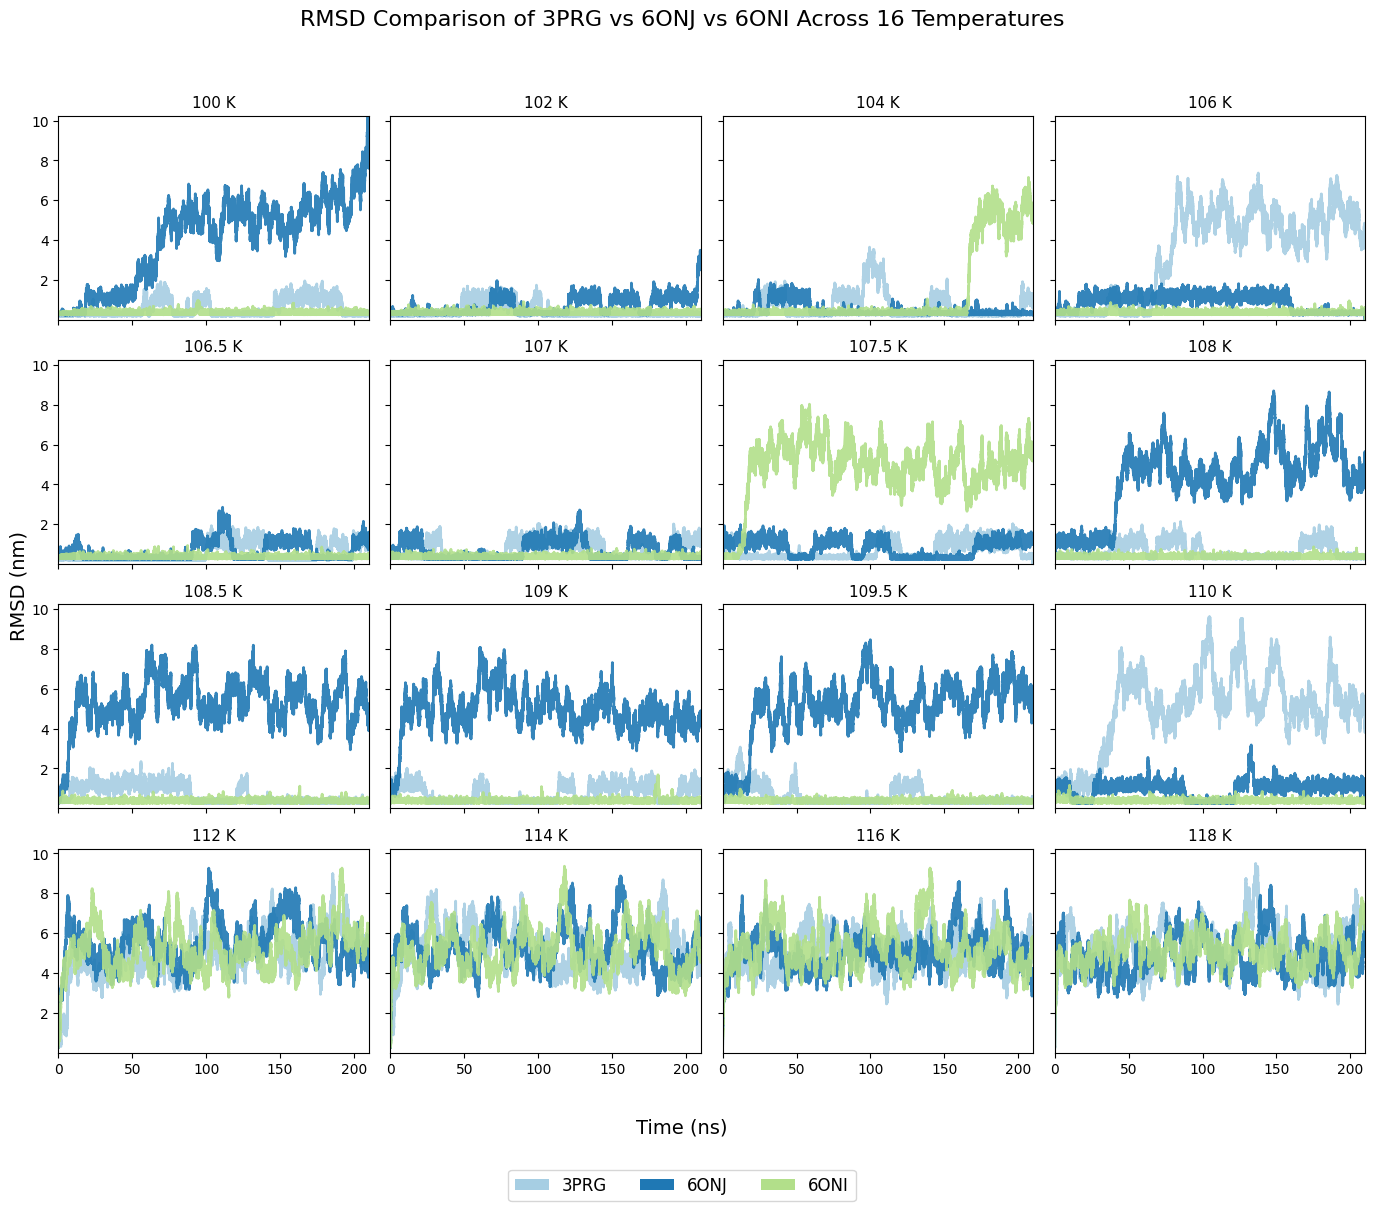

In [48]:
import numpy as np
import matplotlib.pyplot as plt
import os

# =========================
# CONFIG
# =========================
systems = ["3PRG", "6ONJ", "6ONI"]

temps = ["100","102","104","106",
         "106.5","107","107.5","108",
         "108.5","109","109.5","110",
         "112","114","116","118"]

BASE = "Advanced_Analysis"

FIGSIZE = (14, 12)
LW = 2.0
ALPHA = 0.9

# ✅ One qualitative color per system (no white)
colors = {
    "3PRG": "#a6cee3",   # teal
    "6ONJ": "#1f78b4",   # blue
    "6ONI": "#b2df8a",   # green
}

# =========================
# ✅ GLOBAL SCALING (ALL SYSTEMS, ALL TEMPS)
# =========================
all_x = []
all_y = []

for sys in systems:
    for T in temps:
        fname = f"{BASE}/{sys}/{T}/RMSD_{sys}_{T}.xvg"
        if os.path.isfile(fname):
            data = np.loadtxt(fname, comments=["@", "#"])
            time = data[:, 0] / 1000.0      # ✅ CHANGED: convert to ns here
            rmsd = data[:, 1]
            all_x.append(time)
            all_y.append(rmsd)

all_x = np.concatenate(all_x)
all_y = np.concatenate(all_y)

X_LIM = (all_x.min(), all_x.max())
Y_LIM = (all_y.min(), all_y.max())

# =========================
# ✅ 4 × 4 GRID (ONE TEMP PER PANEL)
# =========================
fig, axes = plt.subplots(4, 4, figsize=FIGSIZE, sharex=True, sharey=True)
axes = axes.flatten()

for ax, T in zip(axes, temps):

    for sys in systems:
        fname = f"{BASE}/{sys}/{T}/RMSD_{sys}_{T}.xvg"

        if os.path.isfile(fname):
            data = np.loadtxt(fname, comments=["@", "#"])
            time = data[:, 0] / 1000.0      # ✅ CHANGED: convert to ns for plotting
            rmsd = data[:, 1]

            ax.plot(time, rmsd,
                    color=colors[sys],
                    lw=LW,
                    alpha=ALPHA,
                    label=sys)

    ax.set_title(f"{T} K", fontsize=11)
    ax.set_xlim(*X_LIM)      # ✅ now in ns
    ax.set_ylim(*Y_LIM)
    ax.grid(False)

# =========================
# ✅ SINGLE GLOBAL LEGEND
# =========================
from matplotlib.patches import Patch

handles = [
    Patch(facecolor=colors["3PRG"], label="3PRG"),
    Patch(facecolor=colors["6ONJ"], label="6ONJ"),
    Patch(facecolor=colors["6ONI"], label="6ONI"),
]

fig.legend(
    handles=handles,
    loc="lower center",
    ncol=3,
    fontsize=12,
    frameon=True,
    bbox_to_anchor=(0.5, -0.02)
)

# =========================
# ✅ SHARED LABELS
# =========================
fig.supxlabel("Time (ns)", fontsize=14, y=0.04)
fig.supylabel("RMSD (nm)", fontsize=14)  # <- if GROMACS outputs nm, either change label to nm or multiply by 10
fig.suptitle("RMSD Comparison of 3PRG vs 6ONJ vs 6ONI Across 16 Temperatures", fontsize=16)

plt.tight_layout(rect=[0, 0.05, 1, 0.95])

# =========================
# ✅ EXPORT FIGURE (CHANGE FORMAT HERE)
# =========================
plt.savefig("Advanced_Analysis/RMSD_All_Temperatures.png", dpi=300, bbox_inches="tight")
# plt.savefig("Advanced_Analysis/RMSD_All_Temperatures.svg", bbox_inches="tight")
# plt.savefig("Advanced_Analysis/RMSD_All_Temperatures.pdf", bbox_inches="tight")

plt.show()


## 📊 Radius of Gyration (Rg) Across Temperatures

Rg time series for **3PRG**, **6ONJ**, and **6ONI** plotted across all temperatures  
using global axis scaling for direct comparison.

- 🌡️ One panel per temperature (4×4 grid)
- 🎨 System-specific colors
- ⏱️ Time in ns, Rg in nm


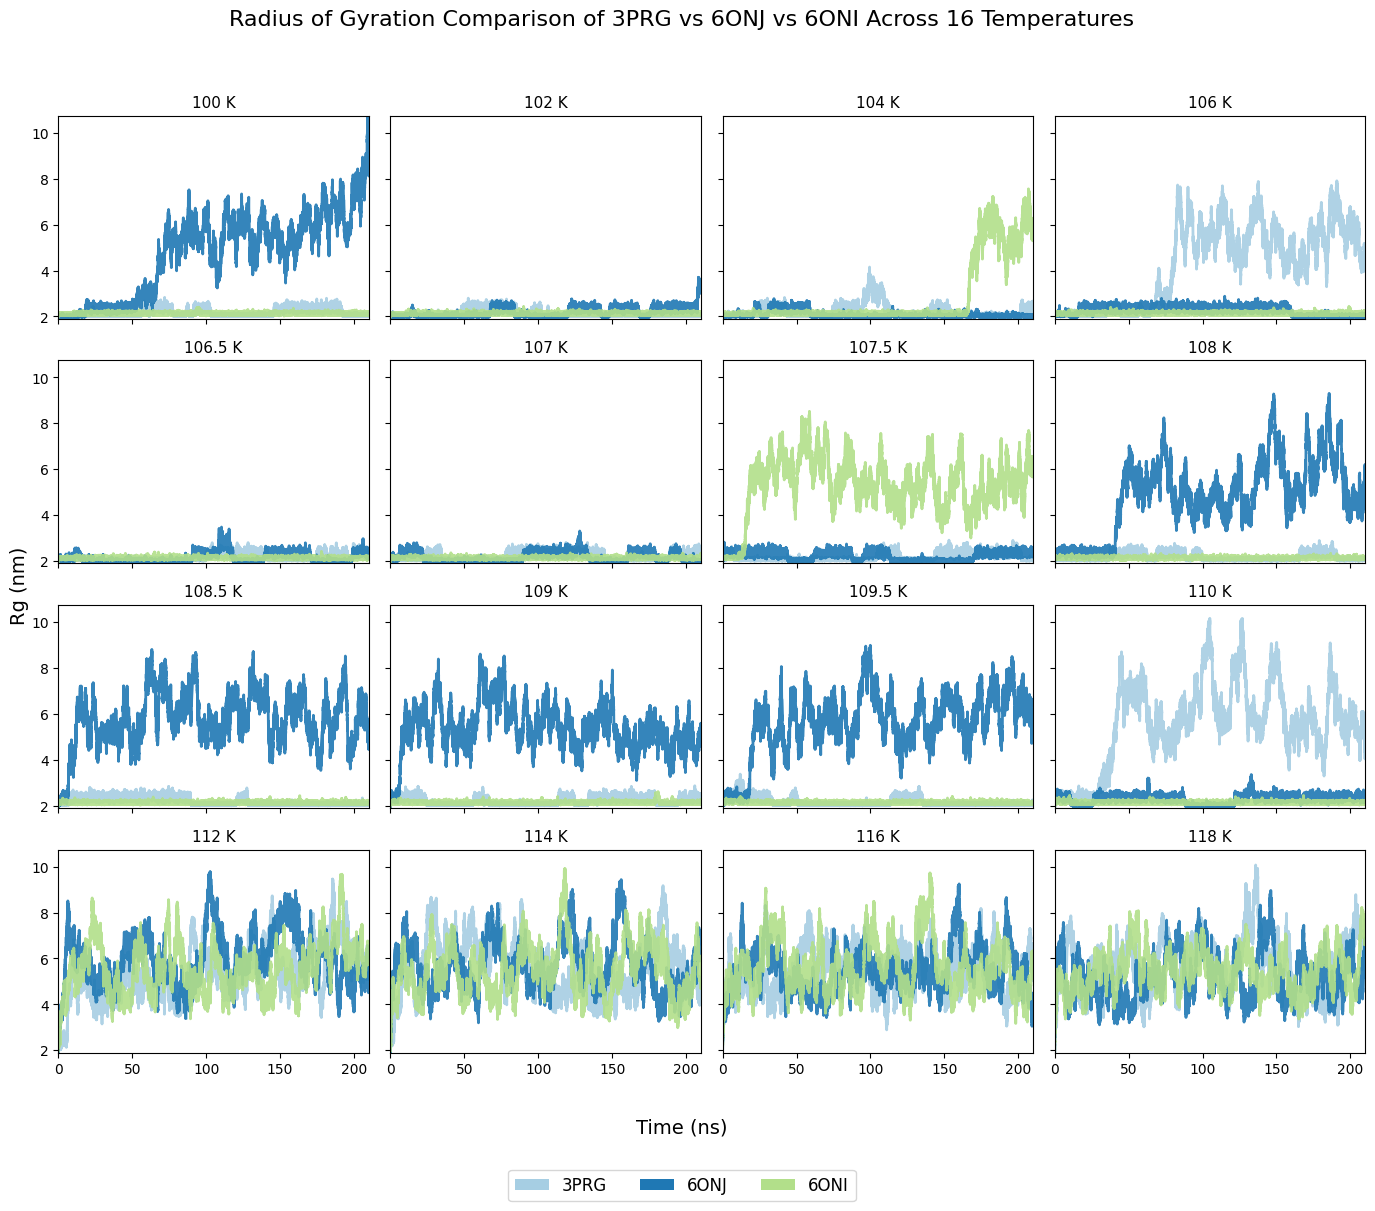

In [29]:
import numpy as np
import matplotlib.pyplot as plt
import os

# =========================
# CONFIG
# =========================
systems = ["3PRG", "6ONJ", "6ONI"]

temps = ["100","102","104","106",
         "106.5","107","107.5","108",
         "108.5","109","109.5","110",
         "112","114","116","118"]

BASE = "Advanced_Analysis"

FIGSIZE = (14, 12)
LW = 2.0
ALPHA = 0.9

# ✅ Qualitative colors (no white)
colors = {
    "3PRG": "#a6cee3",   # teal
    "6ONJ": "#1f78b4",   # blue
    "6ONI": "#b2df8a",   # green
}

# =========================
# ✅ GLOBAL SCALING (ALL SYSTEMS, ALL TEMPS)
# =========================
all_x = []
all_y = []

for sys in systems:
    for T in temps:
        fname = f"{BASE}/{sys}/{T}/Rg_{sys}_{T}.xvg"
        if os.path.isfile(fname):
            data = np.loadtxt(fname, comments=["@", "#"])
            time = data[:, 0] / 1000.0   # ✅ ps → ns
            rg = data[:, 1]
            all_x.append(time)
            all_y.append(rg)

all_x = np.concatenate(all_x)
all_y = np.concatenate(all_y)

X_LIM = (all_x.min(), all_x.max())
Y_LIM = (all_y.min(), all_y.max())

# =========================
# ✅ 4 × 4 GRID (ONE TEMP PER PANEL)
# =========================
fig, axes = plt.subplots(4, 4, figsize=FIGSIZE, sharex=True, sharey=True)
axes = axes.flatten()

for ax, T in zip(axes, temps):

    for sys in systems:
        fname = f"{BASE}/{sys}/{T}/Rg_{sys}_{T}.xvg"

        if os.path.isfile(fname):
            data = np.loadtxt(fname, comments=["@", "#"])
            time = data[:, 0] / 1000.0   # ✅ ps → ns
            rg = data[:, 1]

            ax.plot(
                time, rg,
                color=colors[sys],
                lw=LW,
                alpha=ALPHA,
                label=sys
            )

    ax.set_title(f"{T} K", fontsize=11)
    ax.set_xlim(*X_LIM)
    ax.set_ylim(*Y_LIM)
    ax.grid(False)

# =========================
# ✅ SINGLE GLOBAL LEGEND (RECTANGLES)
# =========================
from matplotlib.patches import Patch

handles = [
    Patch(facecolor=colors["3PRG"], label="3PRG"),
    Patch(facecolor=colors["6ONJ"], label="6ONJ"),
    Patch(facecolor=colors["6ONI"], label="6ONI"),
]

fig.legend(
    handles=handles,
    loc="lower center",
    ncol=3,
    fontsize=12,
    frameon=True,
    bbox_to_anchor=(0.5, -0.02)
)

# =========================
# ✅ SHARED LABELS
# =========================
fig.supxlabel("Time (ns)", fontsize=14, y=0.04)
fig.supylabel("Rg (nm)", fontsize=14)
fig.suptitle("Radius of Gyration Comparison of 3PRG vs 6ONJ vs 6ONI Across 16 Temperatures", fontsize=16)

plt.tight_layout(rect=[0, 0.05, 1, 0.95])

# =========================
# ✅ EXPORT FIGURE (CHANGE FORMAT HERE)
# =========================

# ✅ High-resolution raster
plt.savefig("Advanced_Analysis/Rg_All_Temperatures.png", dpi=300, bbox_inches="tight")

# ✅ True vector formats (uncomment as needed)
# plt.savefig("Advanced_Analysis/Rg_All_Temperatures.svg", bbox_inches="tight")
# plt.savefig("Advanced_Analysis/Rg_All_Temperatures.pdf", bbox_inches="tight")

plt.show()


# Copy RMSD and Rg into SMOG_Figures folder for plotting
Preserves system and temperature subfolders


In [6]:
import os
import shutil

# =========================
# CONFIG
# =========================
systems = ["3PRG", "6ONJ", "6ONI"]

temps = [
    "100","102","104","106",
    "106.5","107","107.5","108",
    "108.5","109","109.5","110",
    "112","114","116","118"
]

INPUT_ROOT  = "Advanced_Analysis"
OUTPUT_ROOT = "/panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Figures"

# Files to copy (extend if needed)
patterns = [
    "RMSD_{sys}_{T}.xvg",
    "Rg_{sys}_{T}.xvg"
]

# =========================
# COPY LOOP
# =========================
for sys in systems:
    for T in temps:

        in_dir = os.path.join(INPUT_ROOT, sys, T)
        if not os.path.isdir(in_dir):
            continue

        out_dir = os.path.join(OUTPUT_ROOT, sys, T)
        os.makedirs(out_dir, exist_ok=True)

        for pat in patterns:
            fname = pat.format(sys=sys, T=T)
            src = os.path.join(in_dir, fname)

            if not os.path.isfile(src):
                continue

            dst = os.path.join(out_dir, fname)
            shutil.copy2(src, dst)

            print(f"✅ Copied: {src} → {dst}")

print("\n🎯 RMSD / Rg files copied to OUTPUT folder successfully")


✅ Copied: Advanced_Analysis/3PRG/100/RMSD_3PRG_100.xvg → /panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Figures/3PRG/100/RMSD_3PRG_100.xvg
✅ Copied: Advanced_Analysis/3PRG/100/Rg_3PRG_100.xvg → /panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Figures/3PRG/100/Rg_3PRG_100.xvg
✅ Copied: Advanced_Analysis/3PRG/102/RMSD_3PRG_102.xvg → /panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Figures/3PRG/102/RMSD_3PRG_102.xvg
✅ Copied: Advanced_Analysis/3PRG/102/Rg_3PRG_102.xvg → /panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Figures/3PRG/102/Rg_3PRG_102.xvg
✅ Copied: Advanced_Analysis/3PRG/104/RMSD_3PRG_104.xvg → /panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Figures/3PRG/104/RMSD_3PRG_104.xvg
✅ Copied: Advanced_Analysis/3PRG/104/Rg_3PRG_104.xvg → /panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Figures/3PRG/104/Rg_3PRG_104.xvg
✅ Copied: Advanced_Analysis/3PRG/106/RMSD_3PRG_106.xvg → /panfs/accrepfs.vampire/d